In [2]:
#Importamos todas las librerias a utilizar en el trabajo (faltan)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 
import category_encoders as ce
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, make_scorer,classification_report, roc_auc_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau 
from tensorflow.keras.optimizers import Adam
from sklearn.compose import make_column_transformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold,  cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.utils import compute_class_weight

# ETAPA 1: Exploración y Modelo Baseline

### Información básica del dataset:
Los datos que contiene provienen de una entidad financiera, la cual lanzó una campaña de marketing a través de llamadas telefónicas. El objetivo del modelo será clasificar si el cliente se suscribirá a un depósito a plazo fijo o no. 
La variable y=1 representa que el usuario sí se suscribió, mientras que y=0 significa que no. 

In [3]:
#Importamos el dataset
bank_marketing = fetch_ucirepo(id=222) 

#Transformamos en DataFrame las features y los targets
X = bank_marketing.data.features 
y = bank_marketing.data.targets 

In [52]:
#Creamos un data frame unificado
df = pd.concat([X,y],axis=1)
print(f'El dataset tiene: {df.shape[0]} filas, y {df.shape[1]} columnas')
df.head()

El dataset tiene: 45211 filas, y 17 columnas


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [80]:
#Vemos los tipos de datos de cada feature
X.info() 

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
dtypes: int64(7), str(9)
memory usage: 5.5 MB


In [4]:
# Binarizar y convertir 'y' en una Serie 1D
y = (y['y'] == 'yes').astype(int) 

# Verificar los resultados
print(y.value_counts())

y
0    39922
1     5289
Name: count, dtype: int64


In [82]:
#Vemos los valores nulos en X
print(X.isnull().sum())

#Vemos si y tiene valores nulos
print(y.isnull().sum())


age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
dtype: int64
0


In [5]:
#Reemplazamos los valores nulos por un valor 'unknown'
X = X.fillna('unknown')

#Vemos si nos quedaron valores nulos
X.isnull().sum()

age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day_of_week    0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
dtype: int64

In [84]:
#Vemos qué valores únicos tiene cada feature
for col in X:
    print(f'{col} - unique: {X[col].nunique()}')

age - unique: 77
job - unique: 12
marital - unique: 3
education - unique: 4
default - unique: 2
balance - unique: 7168
housing - unique: 2
loan - unique: 2
contact - unique: 3
day_of_week - unique: 31
month - unique: 12
duration - unique: 1573
campaign - unique: 48
pdays - unique: 559
previous - unique: 41
poutcome - unique: 4


In [85]:
#Vemos si hay registros duplicados
X.duplicated().any()

np.False_

y
0    88.3
1    11.7
Name: proportion, dtype: float64


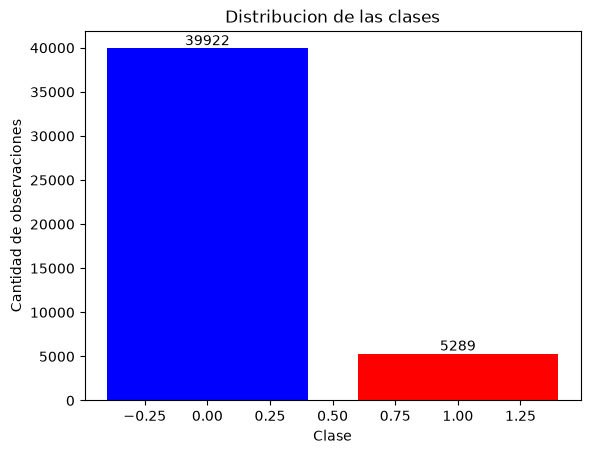

In [86]:
#Vemos la distribución de las clases

print(round(y.value_counts(normalize=True)*100,2))

class_counts = y.value_counts()
plt.bar(class_counts.index, class_counts.values, color = ['blue','red'])
plt.xlabel('Clase')
plt.ylabel('Cantidad de observaciones')
plt.title('Distribucion de las clases')

for clase, cantidad in class_counts.items():
    plt.text(clase, cantidad, str(cantidad), ha="center", va="bottom")

plt.show()


### PARTICIÓN Y TRANSFORMACIÓN DE DATOS

Estrategia de partición elegida: Se ha optado por dividir los datos utilizando una estrategia de estratificación, con el objetivo de conservar las proporciones de las clases en cada conjunto, esta decisión se tomó basándonos en el fuerte desbalance entre las clases y la necesidad de que ambas se vean representadas en cada conjunto. 

In [6]:

X_train, X_dev, y_train, y_dev = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)


print(f"Datos de Entrenamiento (Train): {X_train.shape}")
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")

Datos de Entrenamiento (Train): (36168, 16)
Datos de Desarrollo (Dev): (9043, 16)


In [7]:
#Definimos las variables categóricas y numéricas 
categorical_columns = X.select_dtypes(include='str').columns
categorical_columns

numerical_columns = X.select_dtypes(include=('float','int')).columns
numerical_columns

Index(['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous'],
      dtype='str')

In [8]:
#Creamos los transformadores
OneHot_Encoder = OneHotEncoder(drop='first',handle_unknown='error',sparse_output=False)
Scaler = StandardScaler()

Transformer = make_column_transformer(
    (OneHot_Encoder, categorical_columns),
    (Scaler, numerical_columns),
    remainder='passthrough'
    
)

In [9]:
#Transformamos las variables
X_train_transformed = Transformer.fit_transform(X_train)
X_dev_transformed = Transformer.transform(X_dev)

### Implementación de modelo baseline simple
En este caso, se ha decidido implementar una regresión logística simple. 


In [13]:
modelo_base = LogisticRegression(C=1, max_iter=10000, verbose=3)
modelo_base.fit(X_train_transformed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",3
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None


### Evaluación de métricas
Hemos optado por definir el Recall como métrica principal. La razón de dicha decisión es que, el objetivo del modelo es captar a aquellas personas que se suscribirán (o podrían suscribirse) al depósito del banco, es decir, estamos interesados en capturar a los casos positivos, y evitar falsos negativos, ya que esto significaría perder potenciales clientes (personas que tenian altas chances de suscribirse). Teniendo en cuenta el contexto de marketing (la campaña de la cual proviene este dataset), es fundamental que, si una persona tiene chances de suscribirse, la podamos "captar". Es por esta razón que nuestra métrica adecuada a maximizar será el recall.

In [14]:
# 4. Evaluación en el conjunto de Desarrollo (Dev)
y_pred_dev = modelo_base.predict(X_dev_transformed)

# Cálculos de Métricas
matriz_conf = confusion_matrix(y_dev, y_pred_dev)
exactitud = accuracy_score(y_dev, y_pred_dev)
precision = precision_score(y_dev, y_pred_dev)
recall = recall_score(y_dev, y_pred_dev)
f1 = f1_score(y_dev, y_pred_dev) 

print("\n--- RESULTADOS EN EL CONJUNTO DEV ---")
print("Matriz de Confusión:")
print(matriz_conf)
print(f"Exactitud (Accuracy): {exactitud:.4f}")
print(f"Precisión:            {precision:.4f}")
print(f"Exhaustividad (Recall):{recall:.4f}")
print(f"Puntaje F1 (F1-Score): {f1:.4f}")


--- RESULTADOS EN EL CONJUNTO DEV ---
Matriz de Confusión:
[[7784  201]
 [ 689  369]]
Exactitud (Accuracy): 0.9016
Precisión:            0.6474
Exhaustividad (Recall):0.3488
Puntaje F1 (F1-Score): 0.4533


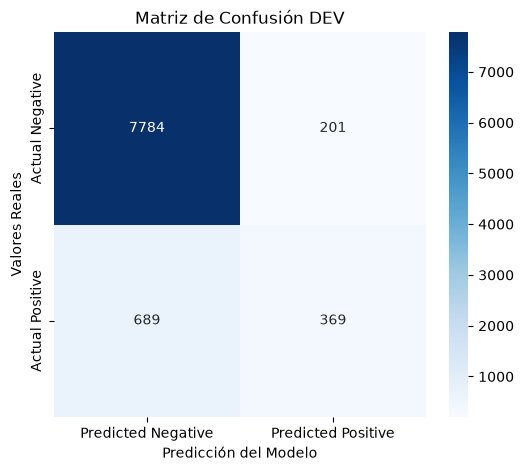

In [15]:
# Crear un mapa de calor de la matriz de confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión DEV')
plt.show()

In [110]:
pipeline2 = Pipeline([
    ('preprocesador', Transformer),
    ('modelo', modelo_base)
])

pipeline2.fit(X_train, y_train)

predicciones2 = pipeline2.predict(X_dev)
print(classification_report(y_dev,predicciones2))

              precision    recall  f1-score   support

           0       0.92      0.97      0.95      3992
           1       0.63      0.35      0.45       529

    accuracy                           0.90      4521
   macro avg       0.78      0.66      0.70      4521
weighted avg       0.89      0.90      0.89      4521



/Users/Camila/Desktop/TrabajoIA/BankMarketingClasificacion_IA/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [111]:
metricas = {
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "average_precision": "average_precision"
}

param_grid = {"modelo__C" : [0.01, 0.06, 0.07 ,0.08, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 1,1.5, 2,2.5, 3, 4 , 5, 6, 7, 8]}

cv = StratifiedKFold( n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline2,
    param_grid=param_grid,
    scoring=metricas,
    refit="recall", #avarage precision
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f"Mejor valor de C: {grid_search.best_params_}")

print(f"Mejor recall promedio en validación cruzada: {grid_search.best_score_}")

Fitting 5 folds for each of 21 candidates, totalling 105 fits


/Users/Camila/Desktop/TrabajoIA/BankMarketingClasificacion_IA/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/Camila/Desktop/TrabajoIA/BankMarketingClasificacion_IA/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=n

Mejor valor de C: {'modelo__C': 6}
Mejor recall promedio en validación cruzada: 0.34555000125599744


/Users/Camila/Desktop/TrabajoIA/BankMarketingClasificacion_IA/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


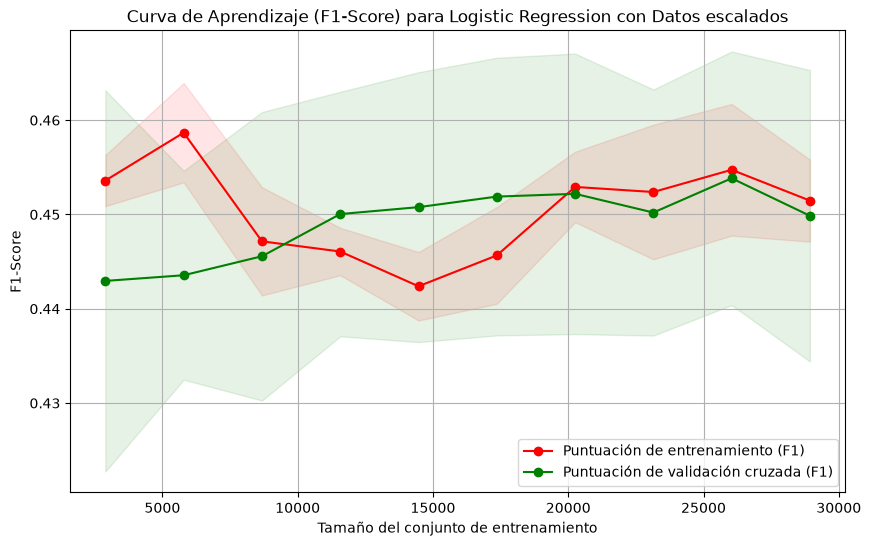

In [16]:
# Definir el scorer para F1-score
f1_scorer = make_scorer(f1_score)

# Generar la curva de aprendizaje con los datos de entrenamiento sin escalar
train_sizes, train_scores, test_scores = learning_curve(
    modelo_base, X_train_transformed, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring=f1_scorer
)

# Calcular medias y desviaciones estándar
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

# Plotear la curva de aprendizaje
plt.figure(figsize=(10, 6))
plt.title("Curva de Aprendizaje (F1-Score) para Logistic Regression con Datos escalados")
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("F1-Score")
plt.grid()

plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1,
                 color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1,
                 color="g")
plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
         label="Puntuación de entrenamiento (F1)")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
         label="Puntuación de validación cruzada (F1)")

plt.legend(loc="best")
plt.show()

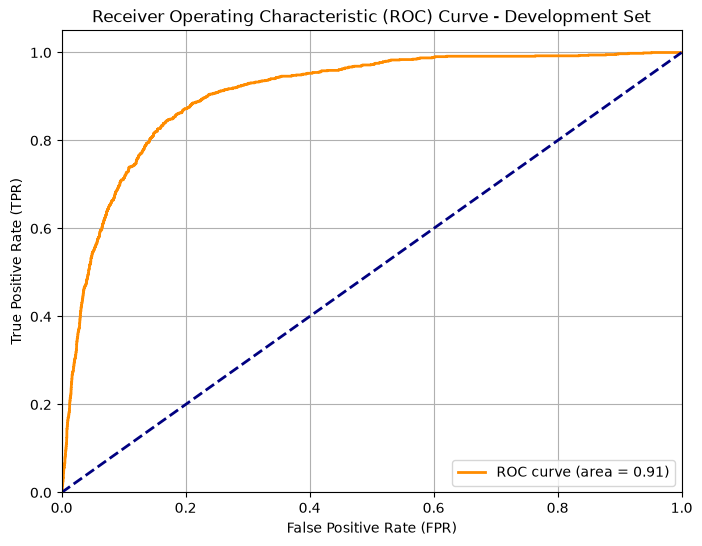

In [17]:
# Obtener las probabilidades de predicción para la clase positiva en el conjunto de desarrollo
y_pred_proba_dev = modelo_base.predict_proba(X_dev_transformed)[:, 1]

# Calcular la curva ROC
fpr, tpr, thresholds = roc_curve(y_dev, y_pred_proba_dev)
roc_auc = auc(fpr, tpr)

# Plotear la curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve - Development Set')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [18]:
nombres_caracteristicas = Transformer.get_feature_names_out()
nombres_caracteristicas = [
    nombre.split('__', 1)[1]
    for nombre in nombres_caracteristicas
]

coeficientes = modelo_base.coef_[0]

#print(f"El punto de partida de la ecuación (Intercepto) es: {sesgo:.4f}\n")


# Creamos el DataFrame
importancia_variables = pd.DataFrame({
    'Característica': nombres_caracteristicas,
    'Peso (Coeficiente)': coeficientes
})

# Calculamos el impacto absoluto
importancia_variables['Impacto Absoluto'] = (
    importancia_variables['Peso (Coeficiente)'].abs()
)

# Ordenamos de mayor a menor impacto
importancia_variables = importancia_variables.sort_values(
    by='Impacto Absoluto',
    ascending=False
)
print("--- TOP 10 VARIABLES CON MÁS IMPACTO ---")
print(importancia_variables.head(10)[['Característica', 'Peso (Coeficiente)', 'Impacto Absoluto']])

--- TOP 10 VARIABLES CON MÁS IMPACTO ---
      Característica  Peso (Coeficiente)  Impacto Absoluto
33  poutcome_success            2.325623          2.325623
20   contact_unknown           -1.595764          1.595764
27         month_mar            1.432003          1.432003
24         month_jan           -1.277590          1.277590
38          duration            1.092146          1.092146
29         month_nov           -0.914143          0.914143
25         month_jul           -0.872532          0.872532
31         month_sep            0.806944          0.806944
30         month_oct            0.802798          0.802798
21         month_aug           -0.764789          0.764789


/var/folders/77/8wfmp3hx6_v0440sd1_2lfnr0000gp/T/ipykernel_61494/390684523.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


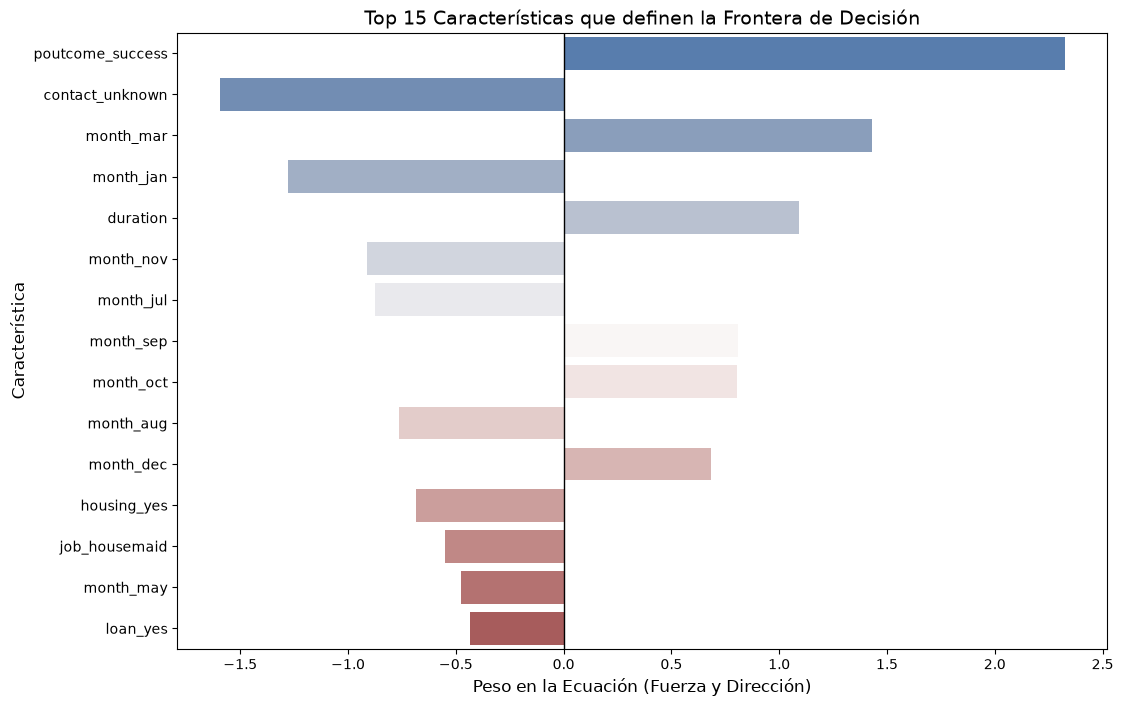

In [19]:
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Peso (Coeficiente)',
    y='Característica',
    data=importancia_variables.head(15),
    palette='vlag'
)
plt.title('Top 15 Características que definen la Frontera de Decisión', fontsize=14)
plt.xlabel('Peso en la Ecuación (Fuerza y Dirección)',fontsize=12)
plt.ylabel('Característica',fontsize=12)
plt.axvline(0, color='black', linewidth=1)
plt.show()

## Etapa 2 — Red neuronal multicapa y análisis de errores 

### Análisis de errores manual
Los errores del modelo baseline pueden ser catalogados como errores de sesgo (underfitting), ya que el modelo simplemente no puede identificar de manera correcta los casos positivos (posee un recall de 0.3535), y no se presenta una gran varianza respecto al test, el cual indica un recall de 0.3422.

Para enfrentar el sesgo de nuestro modelo debemos cambiar su arquitectura y aumentar capacidad, ya que necesitamos que el modelo sea capaz de aprender patrones más complejos para aumentar su capacidad predictiva.

### LEER -CAMI: 
Mientras pasaba todo en limpio lo del archivo 2, tuve que realizar dos modificaciones, que magicamente mejoraron el recall de 87 a 88, y basicamente fue que use el x e y transformed (que incluia el encoder y la estandarizacion, en el otro archivo se usa solamente los datos escalados, al parecer esto mejoró el modelo), segundo - aunque esto no "mejoró" nada - elimine todo lo relacionado al conjunto de datos test, por lo que la matriz de confusión ahora está hecha con los datos DEV.
Luego dejé los pesos calculados con los datos de entrenamiento, y no toqué nada más. 

In [20]:
model = Sequential([
    # Capa de entrada y primera capa oculta con activación ReLU y regularización L2
    Dense(128, activation='relu', input_shape=(X_train_transformed.shape[1],), kernel_regularizer=l2(0.001)),
    Dropout(0.3), # Capa Dropout para mitigar el sobreajuste

    # Segunda capa oculta con activación ReLU y regularización L2
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3), # Capa Dropout

    # Tercera capa oculta con activación ReLU y regularización L2
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3), # Capa Dropout

    # Capa de salida con activación sigmoide para clasificación binaria
    Dense(1, activation='sigmoid')
])

# Compilamos el modelo: usamos 'Adam' como optimizador, 'binary_crossentropy' como función de pérdida para clasificación binaria, y 'recall' como métrica principal.

# Instanciar el optimizador
opt = Adam(learning_rate=0.0001)

model.compile(
    optimizer=opt,
    loss='binary_crossentropy',
    metrics=['recall']
)
# Mostrar un resumen del modelo
print("\nResumen del modelo de red neuronal:")
model.summary()


Resumen del modelo de red neuronal:


/Users/Camila/Desktop/TrabajoIA/BankMarketingClasificacion_IA/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,873 (62.00 KB)

 Trainable params: 15,873 (62.00 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Definir la llamada de Early Stopping
# Monitorea la 'val_loss' (pérdida en el conjunto de validación)
# 'patience=10' significa que esperará 10 épocas sin mejora antes de detenerse
# 'restore_best_weights=True' restaurará los pesos del modelo de la mejor época



early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

"""Como vimos que reduciendo la tasa de aprendizaje de adam converge mejor, podemos usar ReduceROnPlateau para
que cuando la val_loss se estanque, reduzca la tasa de aprendizaje automaticamente reduciendola un poco mas para
mejor convergrncia"""

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

#Definimos los pesos
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
class_weight = dict(zip(classes, weights))

# Entrenar el modelo
print("\nEntrenando el modelo...")
history = model.fit(
    X_train_transformed, y_train,
    epochs=100, 
    batch_size=64, 
    validation_data=(X_dev_transformed, y_dev), # Datos de validación
    class_weight=class_weight, #aca aplicamos los pesos de clase para balancear el desbalance
    callbacks=[early_stopping, reduce_lr], # Aplicar Early Stopping #Agregue acá reduce_lr para el ajuste de tasa de adam automatico
    verbose=1 
)

print("\nEntrenamiento completado.")


Entrenando el modelo...
Epoch 1/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 2s 984us/step - loss: 0.7928 - recall: 0.6646 - val_loss: 0.6405 - val_recall: 0.7854 - learning_rate: 1.0000e-04
Epoch 2/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 737us/step - loss: 0.6395 - recall: 0.7927 - val_loss: 0.5764 - val_recall: 0.8318 - learning_rate: 1.0000e-04
Epoch 3/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step - loss: 0.5884 - recall: 0.8289 - val_loss: 0.5381 - val_recall: 0.8450 - learning_rate: 1.0000e-04
Epoch 4/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step - loss: 0.5651 - recall: 0.8421 - val_loss: 0.5400 - val_recall: 0.8639 - learning_rate: 1.0000e-04
Epoch 5/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 706us/step - loss: 0.5442 - recall: 0.8613 - val_loss: 0.5198 - val_recall: 0.8715 - learning_rate: 1.0000e-04
Epoch 6/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 739us/step - loss: 0.5264 - recall: 0.8674 - val_loss: 0.4977 - val_recall: 0.8658 - learning_rate: 1.0000e-04
Epoch 7/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 7

### Aca cambie la probabilidad a 0.4 y mejoró el recall, paso de 0.87 a 0.90 para la clase objetivo, habria que realizar analisis para obtener el umbral de decision optimo

In [28]:
# Evaluar el modelo en el conjunto de prueba
loss, recall = model.evaluate(X_dev_transformed, y_dev, verbose=0)
print(f"\Recall del modelo en el conjunto de prueba: {recall:.4f}")
print(f"Pérdida del modelo en el conjunto de prueba: {loss:.4f}")


# Realizar predicciones en el conjunto de prueba
y_pred_proba = model.predict(X_dev_transformed)
y_pred = (y_pred_proba > 0.4).astype(int) # Convertir probabilidades a clases binarias (0 o 1)

# Mostrar el reporte de clasificación
print("\nReporte de clasificación en el conjunto de prueba:")
print(classification_report(y_dev, y_pred))

\Recall del modelo en el conjunto de prueba: 0.8658
Pérdida del modelo en el conjunto de prueba: 0.3800
  1/283 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

<>:3: SyntaxWarning: invalid escape sequence '\R'
<>:3: SyntaxWarning: invalid escape sequence '\R'
/var/folders/77/8wfmp3hx6_v0440sd1_2lfnr0000gp/T/ipykernel_61494/1254660944.py:3: SyntaxWarning: invalid escape sequence '\R'
  print(f"\Recall del modelo en el conjunto de prueba: {recall:.4f}")


283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 374us/step

Reporte de clasificación en el conjunto de prueba:
              precision    recall  f1-score   support

           0       0.98      0.81      0.89      7985
           1       0.38      0.90      0.53      1058

    accuracy                           0.82      9043
   macro avg       0.68      0.85      0.71      9043
weighted avg       0.91      0.82      0.84      9043



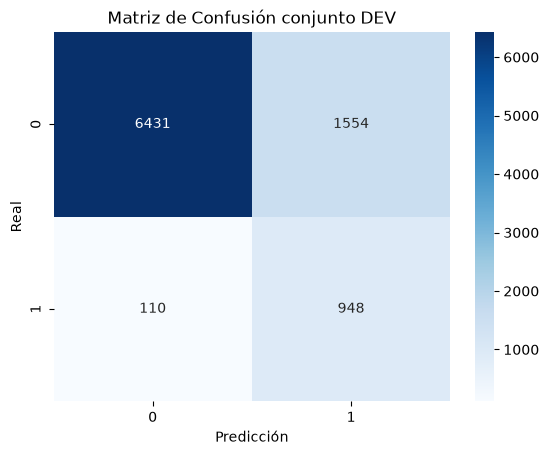

In [30]:
# Mostrar la matriz de confusión
cm = confusion_matrix(y_dev, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión conjunto DEV')
plt.show()

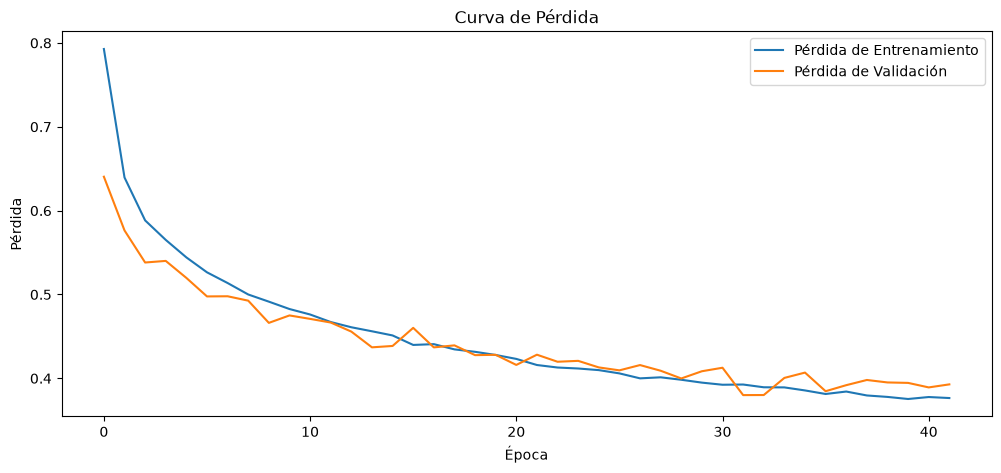

In [24]:
# Visualizar la historia del entrenamiento para detectar sobreajuste
# Curvas de pérdida
plt.figure(figsize=(12, 5))
#plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de Validación')
plt.title('Curva de Pérdida')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()

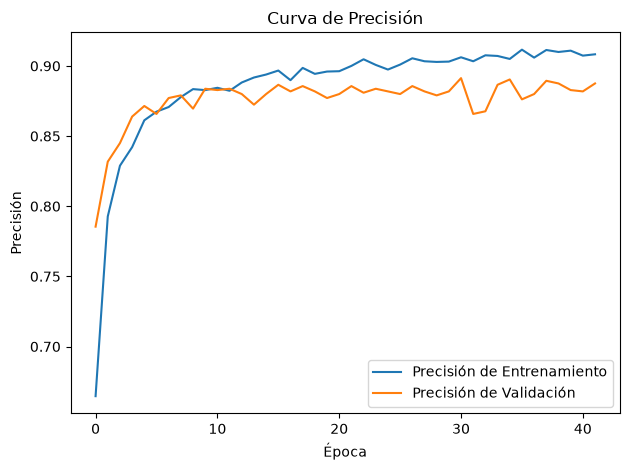

In [25]:
# Curvas de precisión
#plt.subplot(1, 2, 2)
plt.plot(history.history['recall'], label='Precisión de Entrenamiento')
plt.plot(history.history['val_recall'], label='Precisión de Validación')
plt.title('Curva de Precisión')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

plt.tight_layout()
plt.show()